In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/kailani-boop/eds220-hwk2


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

<function matplotlib.pyplot.show(close=None, block=None)>

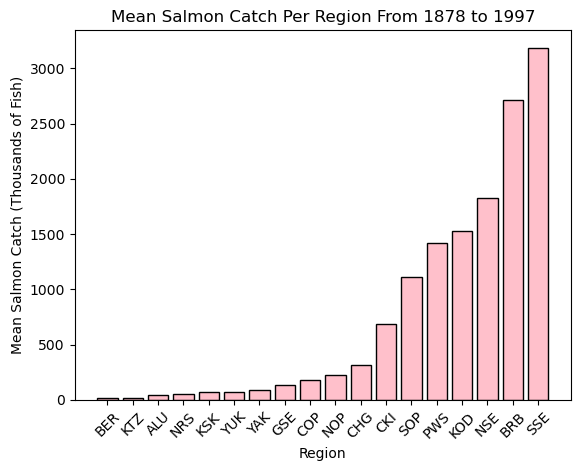

In [24]:
# FINAL CODE
# Importing necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reading in the data
catch_data = pd.read_csv('data/salmon_data.csv')

# Updating the data frame so that notesRegCode isn't included
catch_data = catch_data[['Region', 'Year', 'Species', 'Catch']]

# Updating the 'I' in the Catch column to be a '1' by storing it as a new variable
catch_1 = catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = 1

# Reassigning catch column to the original catch column but as an integer
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# Creating a new data frame with Region and Catch columns
# The new df's catch column is the mean of the catches grouped by region
avg_region = catch_data.groupby('Region').mean('Catch').sort_values(by = 'Catch', ascending = True) # Ascending order

# Bar plot of salmon catches by region in a specific year time frame
plt.bar(
    avg_region.index.astype(str), # The index is now the region
    avg_region['Catch'].values,  # Set the mean catch values as the values of the bar plot
    color = 'pink',  # Color of the bars
    edgecolor = 'black'  # Color of the lines around the bars
)
# Labels for the axis' and title
plt.xlabel('Region')
plt.xticks(rotation = 45)  # Rotate the ticks so that the codes are legible
plt.ylabel('Mean Salmon Catch (Thousands of Fish)')
plt.title('Mean Salmon Catch Per Region From 1878 to 1997')
# So the plot shows
plt.show

## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [21]:
# a.
# Importing necessary packages
import pandas as pd
import numpy as np

# Reading in the data
catch_data = pd.read_csv('data/salmon_data.csv')

# Looking at the head of the data frame
catch_data.head()

,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [3]:
# b.
# Looking at the info of the data frame
catch_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   object
dtypes: int64(1), object(4)
memory usage: 333.7+ KB


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

I decided to use `.info()` because it gives me a lot of information in one go, rather than using multiple different data exploration techniques. I get the names of the columns, shape of the data frame, the types of each column, the class of the variable, and the number of non-null values in each column. There are no null values anywhere in the data frame. Four of the columns are objects and one has integer values. 

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [4]:
# Storing the unique values of notesRegCode in a new variable
notes_unique = catch_data['notesRegCode'].unique()

# Printing the new variables
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [5]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [6]:
# Updating the data frame so that notesRegCode isn't included
catch_data = catch_data[['Region', 'Year', 'Species', 'Catch']]

In [7]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


_Catch should also be an `int64` type column. Catch is the number of fish caught. Right now, it's an object. The rest of the columns appear to be the correct type._

In [8]:
# Looking at the type of each column in the data frame
catch_data.dtypes

Region     object
Year        int64
Species    object
Catch      object
dtype: object

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [9]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [10]:
# Finding a row where the catch number was `I` instead of 1
# Storing it as a new variable
catch_I = catch_data.loc[catch_data['Catch'] == 'I']
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [11]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [12]:
# Updating the 'I' to be a '1'
catch_1 = catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = 1

# Print catch_1
catch_1

1

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [13]:
# Reassigning catch column to the original catch column but as an integer
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# Storing the type of the reassigned column as a new variable
catch_column_type = catch_data['Catch'].dtypes
# Calling the new variable
catch_column_type # int64

dtype('int64')

In [14]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [15]:
# Creating a new data frame with Region and Catch columns
# The new df's catch column is the mean of the catches grouped by region
avg_region = catch_data.groupby('Region').mean('Catch').sort_values(by = 'Catch', ascending = True)
avg_region

,Year,Catch
Region,,
BER,1946.5,16.372549
KTZ,1955.0,18.836145
ALU,1954.0,40.383908
NRS,1979.0,51.502703
KSK,1955.0,67.642353
YUK,1957.0,68.645570
YAK,1949.5,91.922917
GSE,1918.5,133.841463
COP,1950.5,179.223404


In [16]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<function matplotlib.pyplot.show(close=None, block=None)>

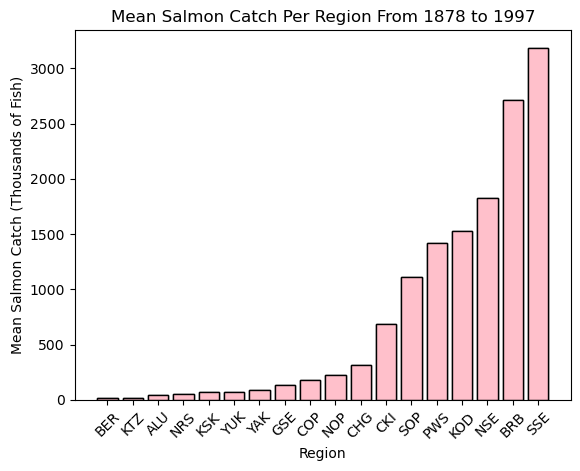

In [18]:
# Importing the package needed to plot things
import matplotlib.pyplot as plt

# Bar plot of salmon catches by region in a specific year time frame
plt.bar(
    avg_region.index.astype(str), # The index is now the region
    avg_region['Catch'].values,  # Set the mean catch values as the values of the bar plot
    color = 'pink',  # Color of the bars
    edgecolor = 'black'  # Color of the lines around the bars
)
# Labels for the axis' and title
plt.xlabel('Region')
# Rotate the ticks so that the codes are legible
plt.xticks(rotation = 45) 
plt.ylabel('Mean Salmon Catch (Thousands of Fish)')
plt.title('Mean Salmon Catch Per Region From 1878 to 1997')
# So the plot shows
plt.show

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

There's a big discrepancy between the mean salmon catches in different regions. Southern Southeast Alaska has the largest mean at 3000+ salmon catches in terms of thousands of fish. Bering River Subarea Copper River Subarea has the smallest mean, which appears to be around 0. Seven of the regions: Cook Inlet Management Area, South Peninsula Subarea, Prince William Sound Subarea, Kodiak Management Area, Northern Southeast Alaska, Bristol Bay Management Area, and Southern Southeast Alaska have the largest means. Meanwhile the other 11 regions' means are below 500 salmon catches (in thousands of fish). There doesn't appear to be a clear pattern or reason why some regions have higher means when looking at the original data repository. The regions are divided between management areas or subareas and four different region codes. There's some regions with a low mean and a high mean in the same area code. And the same for management vs subareas. 

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [19]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!